# Data Analysis & Visualization (DAV) — Lab 3
## Topic: Chart Effectiveness, Visual Appropriateness, Color Selection, Accessibility (WCAG), and Deceptive Visualizations
---
- **Student Roll Number:** `24i-2514`
- **Section:** `DS-5B`
- **Course:** Data Analysis and Visualization (DAV)
- **Dataset:** Superstore Sales & Profit Dataset (`Superstore.csv`)


---
## Step 0: Setup, Library Imports, and Initial Data Preparation
We start by importing standard, beginner-friendly Python libraries for data manipulation and visualization:
- `pandas`: for loading and grouping tabular data.
- `matplotlib.pyplot`: for creating clean, customized charts.
- `seaborn`: for statistical visualization and heatmaps.
- `numpy`: for basic mathematical operations.

In [1]:
# Step 0: Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean visual theme for all plots
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load the Superstore dataset using standard encoding
df = pd.read_csv('Superstore.csv', encoding='windows-1252')

# Convert 'Order Date' to datetime so we can group by month easily
df['Order Date'] = pd.to_datetime(df['Order Date'])

# Create a clean 'YearMonth' column in YYYY-MM format (e.g. '2014-01')
df['YearMonth'] = df['Order Date'].dt.to_period('M').astype(str)

# Clean up column names by removing any leading or trailing spaces
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Number of records (rows):", df.shape[0])
print("Number of features (columns):", df.shape[1])
df[['Order Date', 'YearMonth', 'Region', 'Category', 'Sub-Category', 'Sales', 'Profit', 'Discount']].head()

Dataset loaded successfully!
Number of records (rows): 9994
Number of features (columns): 22


,Order Date,YearMonth,Region,Category,Sub-Category,Sales,Profit,Discount
0,2016-11-08,2016-11,South,Furniture,Bookcases,261.9600,41.9136,0.00
1,2016-11-08,2016-11,South,Furniture,Chairs,731.9400,219.5820,0.00
2,2016-06-12,2016-06,West,Office Supplies,Labels,14.6200,6.8714,0.00
3,2015-10-11,2015-10,South,Furniture,Tables,957.5775,-383.0310,0.45
4,2015-10-11,2015-10,South,Office Supplies,Storage,22.3680,2.5164,0.20


---
## Task 1: Same Data, Multiple Chart Types
> **Manual Prompt:** Take one dataset (e.g. monthly sales) already summarized by month and render it as a **bar chart**, a **line chart**, and a **pie chart**.<br>
> *Question to answer:* **"Which chart shows the trend best, and which one hides it? Why?"**

In [2]:
# Summarize total sales by month
monthly_sales = df.groupby('YearMonth')['Sales'].sum().reset_index()

# Display the first few months
print("Summary of monthly sales (first 5 rows):")
print(monthly_sales.head())

Summary of monthly sales (first 5 rows):
  YearMonth      Sales
0   2014-01  14236.895
1   2014-02   4519.892
2   2014-03  55691.009
3   2014-04  28295.345
4   2014-05  23648.287


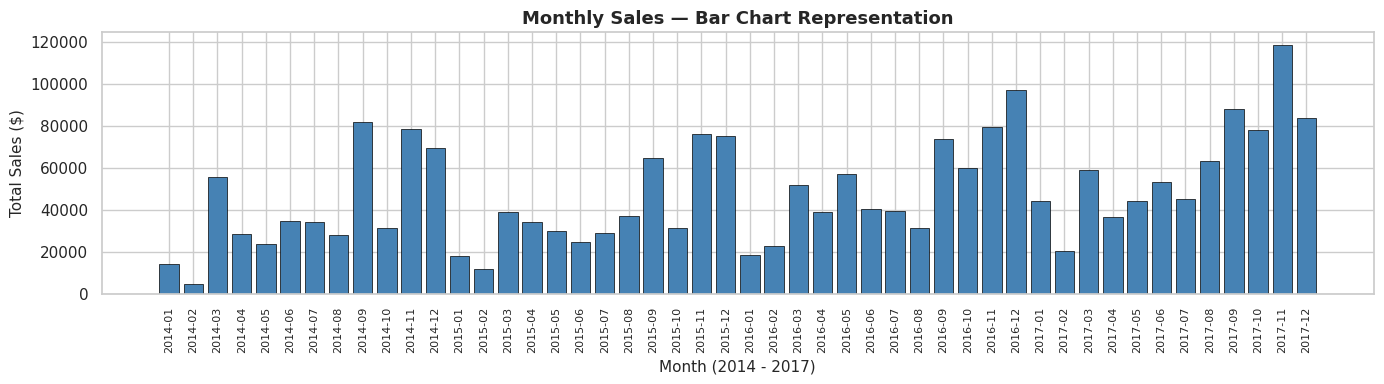

In [3]:
# 1. Bar Chart of Monthly Sales
plt.figure(figsize=(14, 4))
plt.bar(monthly_sales['YearMonth'], monthly_sales['Sales'], color='steelblue', edgecolor='black', linewidth=0.5)
plt.title('Monthly Sales — Bar Chart Representation', fontsize=13, fontweight='bold')
plt.xlabel('Month (2014 - 2017)', fontsize=11)
plt.ylabel('Total Sales ($)', fontsize=11)
plt.xticks(rotation=90, fontsize=8)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

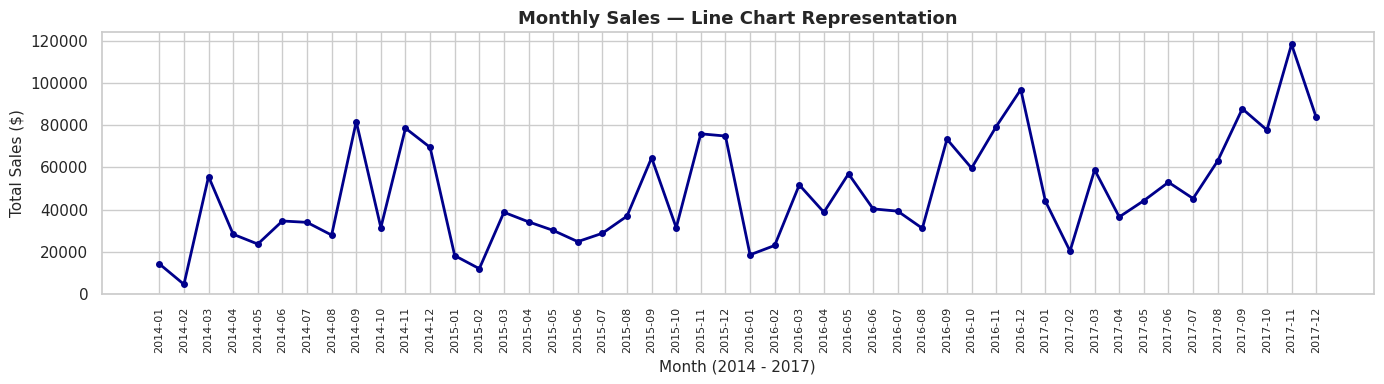

In [4]:
# 2. Line Chart of Monthly Sales
plt.figure(figsize=(14, 4))
plt.plot(monthly_sales['YearMonth'], monthly_sales['Sales'], marker='o', markersize=4, color='darkblue', linewidth=2)
plt.title('Monthly Sales — Line Chart Representation', fontsize=13, fontweight='bold')
plt.xlabel('Month (2014 - 2017)', fontsize=11)
plt.ylabel('Total Sales ($)', fontsize=11)
plt.xticks(rotation=90, fontsize=8)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

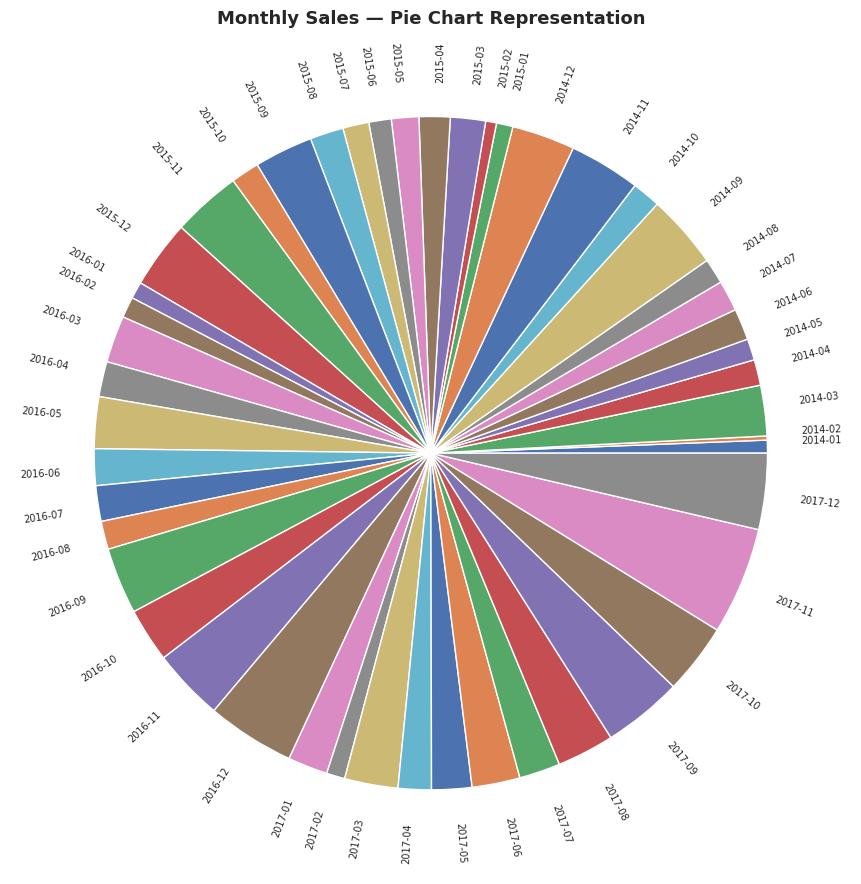

In [5]:
# 3. Pie Chart of Monthly Sales
plt.figure(figsize=(9, 9))
# Plotting all 48 months on a pie chart
plt.pie(monthly_sales['Sales'], labels=monthly_sales['YearMonth'], rotatelabels=True, textprops={'fontsize': 7})
plt.title('Monthly Sales — Pie Chart Representation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Task 1 Analysis & Discussion:
**1. Which chart shows the trend best?**
* **The Line Chart shows the trend best.**
* *Why:* Time is an intrinsically ordered and continuous variable. In a line chart, data points are connected sequentially along a continuous horizontal axis. The slope of the line enables human pre-attentive vision to immediately detect trajectory, growth rate, and recurring seasonal cycles (e.g., strong sales spikes every November and December, followed by January slumps).

**2. Which chart hides the trend completely?**
* **The Pie Chart hides the trend completely.**
* *Why:* A pie chart encodes values using **angles and 2D slice areas**—channels that human perception judges with very low precision (*Stevens' Power Law*). Furthermore, a circle breaks the linear chronological sequence of time, placing the 48 months into an unreadable "color wheel" where it is impossible to tell whether sales are growing, shrinking, or fluctuating over the 4-year period.

**3. What about the Bar Chart?**
* The bar chart is effective for comparing specific discrete values between adjacent months because bars use **length and common baseline** (very strong channels). However, with 48 distinct bars, visual clutter and vertical separation make it harder to observe the smooth overarching trajectory than the line chart.

---
## Task 2: Effectiveness & Visual Appropriateness
> **Manual Prompt:** For each of the 4 statements below, pick the best chart type, build it, and justify in 1–2 sentences why it fits and why the "weak choice" would mislead or underperform.

### Statement 2.1: "Compare total sales across the top 5 sub-categories."
* **Best Form:** Horizontal / Vertical Bar Chart
* **Weak Choice:** Pie Chart or Radar Chart

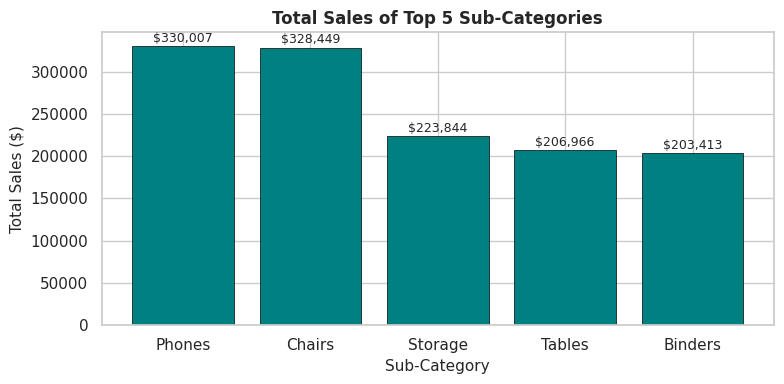

In [6]:
# Top 5 sub-categories by sales
top5_subcategories = df.groupby('Sub-Category')['Sales'].sum().nlargest(5).reset_index()

plt.figure(figsize=(8, 4))
plt.bar(top5_subcategories['Sub-Category'], top5_subcategories['Sales'], color='teal', edgecolor='black', linewidth=0.5)
plt.title('Total Sales of Top 5 Sub-Categories', fontsize=12, fontweight='bold')
plt.xlabel('Sub-Category', fontsize=11)
plt.ylabel('Total Sales ($)', fontsize=11)
plt.ylim(bottom=0)

# Add exact value labels on top of bars for clarity
for i, row in top5_subcategories.iterrows():
    plt.text(i, row['Sales'] + 5000, f"${row['Sales']:,.0f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

**Justification:**
> - **Why Bar Chart Fits:** Bar charts encode numeric magnitudes using **length along an aligned common scale starting at zero**, allowing the human eye to instantly distinguish close differences (e.g., Phones at \$330k vs. Chairs at \$328k).
> - **Why Weak Choice (Pie Chart) Fails:** Pie charts encode values as angles and 2D slice areas, which the human brain consistently misjudges, making it nearly impossible to tell which slice is larger when values are close.

### Statement 2.2: "Show the revenue trend over time."
* **Best Form:** Line Chart (reusing monthly sales data)
* **Weak Choice:** Bar Chart (with 48 discrete bars)

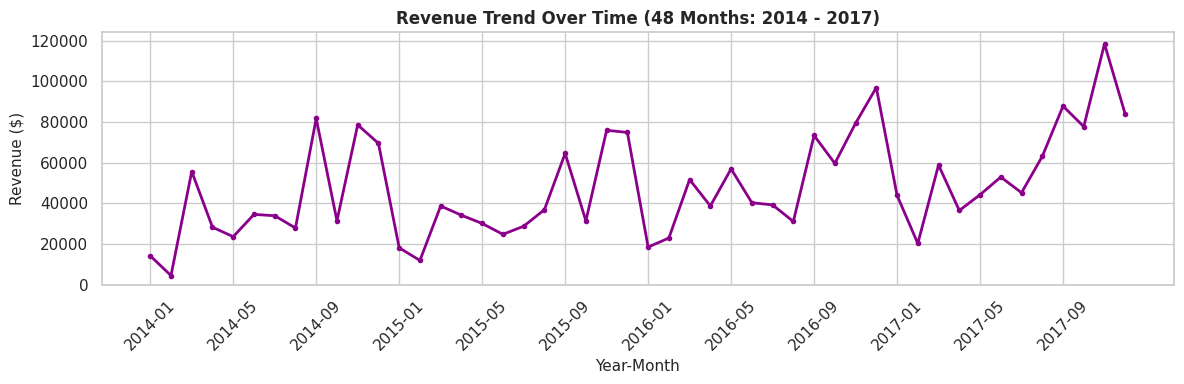

In [7]:
# Line chart showing revenue trend over time
plt.figure(figsize=(12, 4))
plt.plot(monthly_sales['YearMonth'], monthly_sales['Sales'], color='darkmagenta', marker='o', markersize=3, linewidth=2)
plt.title('Revenue Trend Over Time (48 Months: 2014 - 2017)', fontsize=12, fontweight='bold')
plt.xlabel('Year-Month', fontsize=11)
plt.ylabel('Revenue ($)', fontsize=11)

# Display every 4th month tick to keep labels readable
tick_positions = range(0, len(monthly_sales), 4)
tick_labels = monthly_sales['YearMonth'].iloc[tick_positions]
plt.xticks(ticks=tick_positions, labels=tick_labels, rotation=45)
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

**Justification:**
> - **Why Line Chart Fits:** Time is continuous and ordered; connecting sequential points with a line emphasizes directional movement, slope velocity, and recurring annual fourth-quarter peaks.
> - **Why Weak Choice (Bar Chart) Fails:** A bar chart with 48 separate columns fragments the time sequence into isolated blocks, creating excessive visual clutter that interrupts the brain's perception of a smooth continuous trend.

### Statement 2.3: "Show the distribution of order-line sales values."
* **Best Form:** Histogram (using raw `Sales` column)
* **Weak Choice:** Bar Chart of Averages

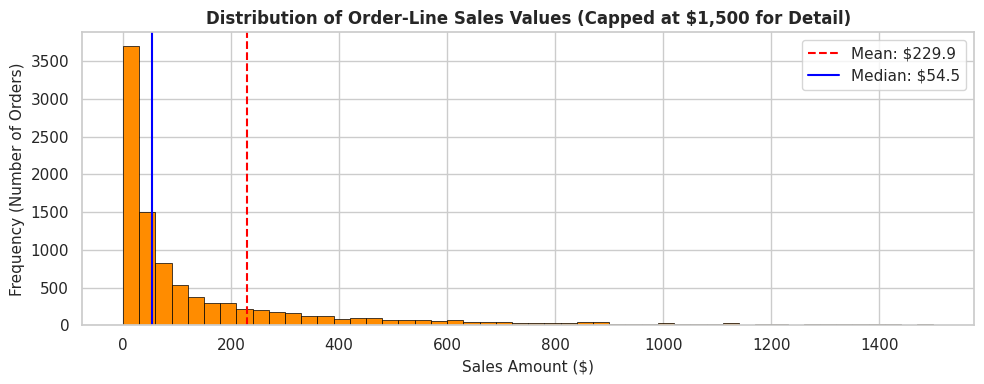

In [8]:
# Histogram of raw sales values
plt.figure(figsize=(10, 4))
# We limit display to $1,500 to show the dense low-end distribution clearly
plt.hist(df['Sales'], bins=50, range=(0, 1500), color='darkorange', edgecolor='black', linewidth=0.5)
plt.title('Distribution of Order-Line Sales Values (Capped at $1,500 for Detail)', fontsize=12, fontweight='bold')
plt.xlabel('Sales Amount ($)', fontsize=11)
plt.ylabel('Frequency (Number of Orders)', fontsize=11)

# Highlight median and mean to show extreme skewness
mean_sales = df['Sales'].mean()
median_sales = df['Sales'].median()
plt.axvline(mean_sales, color='red', linestyle='--', linewidth=1.5, label=f'Mean: ${mean_sales:.1f}')
plt.axvline(median_sales, color='blue', linestyle='-', linewidth=1.5, label=f'Median: ${median_sales:.1f}')
plt.legend()
plt.tight_layout()
plt.show()

**Justification:**
> - **Why Histogram Fits:** A histogram groups continuous numbers into bins to reveal the true distributional shape, showing severe right-skewness where 50% of orders are under \$54 (median) despite occasional large \$20,000 orders.
> - **Why Weak Choice (Bar of Averages) Fails:** A single bar showing the mean (\$230) collapses thousands of data points into one number, completely concealing the variance, spread, extreme positive outliers, and true customer buying pattern.

### Statement 2.4: "Show the relationship between discount level and profit."
* **Best Form:** Scatter Plot (using raw `Discount` and `Profit` columns)
* **Weak Choice:** Line Chart

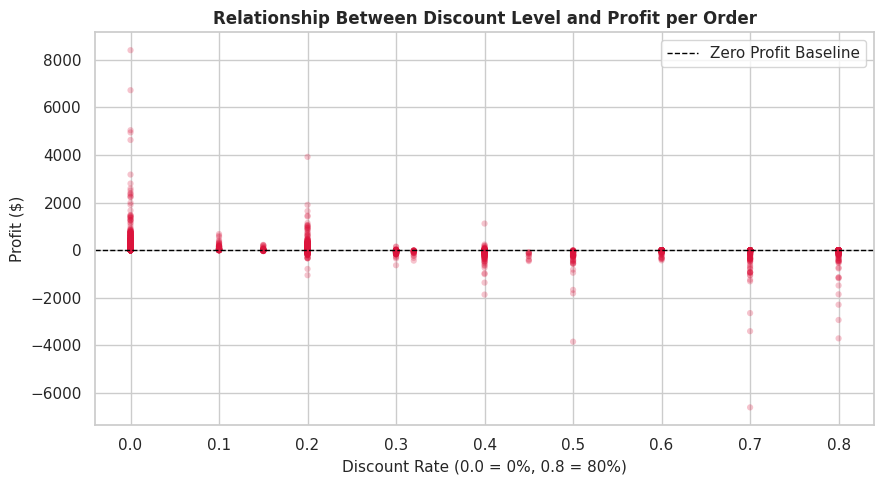

In [9]:
# Scatter plot of raw Discount vs. Profit
plt.figure(figsize=(9, 5))
plt.scatter(df['Discount'], df['Profit'], alpha=0.25, color='crimson', edgecolors='none', s=20)
plt.axhline(0, color='black', linestyle='--', linewidth=1, label='Zero Profit Baseline')
plt.title('Relationship Between Discount Level and Profit per Order', fontsize=12, fontweight='bold')
plt.xlabel('Discount Rate (0.0 = 0%, 0.8 = 80%)', fontsize=11)
plt.ylabel('Profit ($)', fontsize=11)
plt.legend()
plt.tight_layout()
plt.show()

**Justification:**
> - **Why Scatter Plot Fits:** A scatter plot maps two continuous variables across orthogonal 2D coordinates (the most accurate visual channel), immediately revealing that profits plunge steeply into negative territory once discounts exceed 20% (0.2).
> - **Why Weak Choice (Line Chart) Fails:** Connecting individual unordered transactions with lines creates a nonsensical web of intersecting zigzags, falsely implying a sequential progression or time-dependence between unrelated orders.

---
## Task 3: Color Selection Theory & Palettes
Color must be chosen based on **data semantics**, not mere aesthetics. We demonstrate the three fundamental palette types:
1. **Categorical Palette:** For unordered, nominal groups (Region).
2. **Sequential Palette:** For ordered numeric magnitude from low to high (Region $\times$ Category Heatmap).
3. **Diverging Palette:** For data with a critical midpoint / zero boundary (Monthly Profit with gains and losses).

### Task 3(a): Recolor Region Sales with a Proper Categorical Palette
- The 4 geographical regions (Central, East, South, West) have **no inherent numerical ordering**.
- Therefore, we use distinct, distinguishable qualitative hues (max $\le 8$ colors) rather than a sequential rainbow.

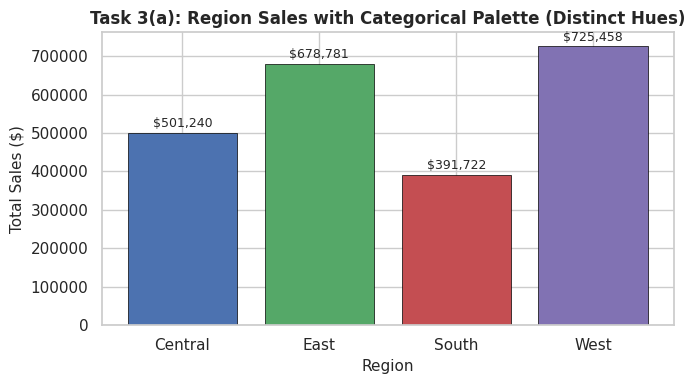

In [10]:
# Task 3(a): Total sales by region
region_sales = df.groupby('Region')['Sales'].sum().reset_index()

# Define a clean 4-color categorical palette (distinct hues)
categorical_colors = ['#4C72B0', '#55A868', '#C44E52', '#8172B3']

plt.figure(figsize=(7, 4))
plt.bar(region_sales['Region'], region_sales['Sales'], color=categorical_colors, edgecolor='black', linewidth=0.5)
plt.title('Task 3(a): Region Sales with Categorical Palette (Distinct Hues)', fontsize=12, fontweight='bold')
plt.xlabel('Region', fontsize=11)
plt.ylabel('Total Sales ($)', fontsize=11)
plt.ylim(bottom=0)

for i, val in enumerate(region_sales['Sales']):
    plt.text(i, val + 15000, f"${val:,.0f}", ha='center', fontsize=9)

plt.tight_layout()
plt.show()

### Task 3(b): Heatmap with a Sequential Palette (Region $\times$ Category)
- Encodes numerical magnitude (low sales $\rightarrow$ high sales).
- Uses a single hue from light to dark (e.g., `Blues`). Lighter shades represent smaller sales; darker saturated shades represent higher sales.

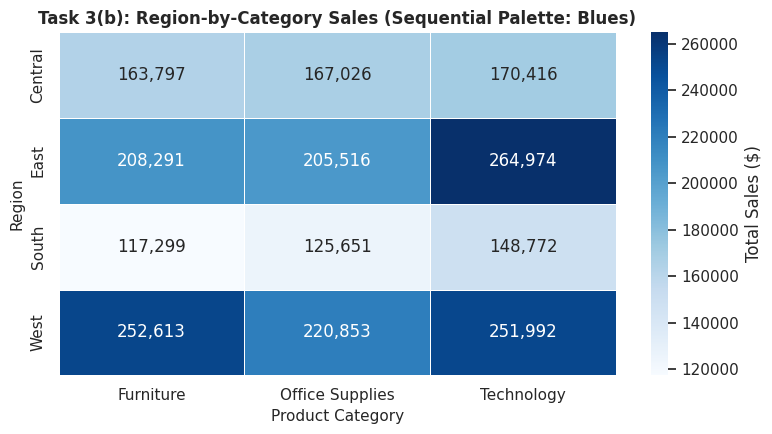

In [11]:
# Task 3(b): Create pivot table of Sales by Region and Category
region_category_sales = df.pivot_table(index='Region', columns='Category', values='Sales', aggfunc='sum')

plt.figure(figsize=(8, 4.5))
# Using the sequential palette 'Blues'
sns.heatmap(region_category_sales, annot=True, fmt=',.0f', cmap='Blues', cbar_kws={'label': 'Total Sales ($)'}, linewidths=0.5)
plt.title('Task 3(b): Region-by-Category Sales (Sequential Palette: Blues)', fontsize=12, fontweight='bold')
plt.xlabel('Product Category', fontsize=11)
plt.ylabel('Region', fontsize=11)
plt.tight_layout()
plt.show()

### Task 3(c): Monthly Profit with a Diverging Palette
- Profit is a **signed metric** that crosses zero: positive values represent **profit (gain)** while negative values represent **deficit (loss)**.
- A **diverging palette** uses two contrasting hues meeting at a neutral baseline (zero).

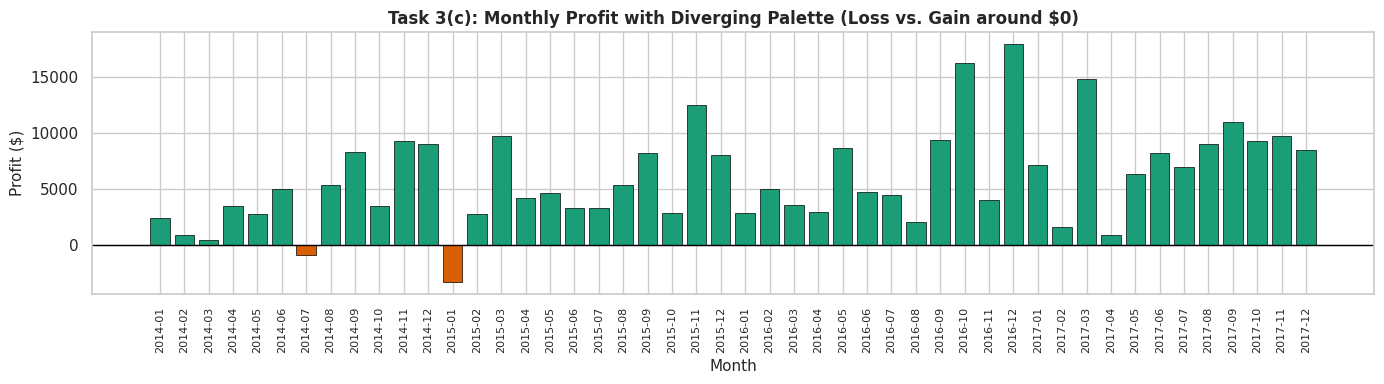

Months operating at a net loss:
YearMonth     Profit
  2014-07  -841.4826
  2015-01 -3281.0070


In [12]:
# Task 3(c): Total profit by month
monthly_profit = df.groupby('YearMonth')['Profit'].sum().reset_index()

# Diverging color assignment: Red/Orange for losses (< 0), Teal/Green for profits (>= 0)
diverging_colors = []
for profit in monthly_profit['Profit']:
    if profit < 0:
        diverging_colors.append('#d95f02')  # Distinct Orange-Red for loss
    else:
        diverging_colors.append('#1b9e77')  # Distinct Teal-Green for profit

plt.figure(figsize=(14, 4))
plt.bar(monthly_profit['YearMonth'], monthly_profit['Profit'], color=diverging_colors, edgecolor='black', linewidth=0.5)
plt.axhline(0, color='black', linewidth=1)
plt.title('Task 3(c): Monthly Profit with Diverging Palette (Loss vs. Gain around $0)', fontsize=12, fontweight='bold')
plt.xlabel('Month', fontsize=11)
plt.ylabel('Profit ($)', fontsize=11)
plt.xticks(rotation=90, fontsize=8)
plt.tight_layout()
plt.show()

# Show loss months
loss_months = monthly_profit[monthly_profit['Profit'] < 0]
print("Months operating at a net loss:")
print(loss_months.to_string(index=False))

---
## Task 4: Digital Accessibility, WCAG Contrast & Colorblindness
Visualizations must be accessible to all audiences, including users with visual impairments or color vision deficiencies.
- **WCAG AA Compliance:** Requires a contrast ratio of at least **4.5:1** for regular text and critical elements against their background.
- **Redundant Encoding:** Information must never be communicated through color alone.

### Task 4(a): WCAG Relative Luminance & Contrast Ratio Function
We write an easy-to-understand Python function implementing the official **W3C WCAG 2.1 formula**:
1. Convert RGB values (0–255) to normalized scale (0–1).
2. Apply gamma expansion to obtain linear RGB values:
   $$\text{If } C \le 0.03928 \implies C_{lin} = \frac{C}{12.92} \quad \text{else} \quad C_{lin} = \left(\frac{C + 0.055}{1.055}\right)^{2.4}$$
3. Compute relative luminance ($L$):
   $$L = 0.2126 \times R_{lin} + 0.7152 \times G_{lin} + 0.0722 \times B_{lin}$$
4. Calculate contrast ratio:
   $$\text{Contrast Ratio} = \frac{L_1 + 0.05}{L_2 + 0.05} \quad \text{(where } L_1 \text{ is the lighter color)}$$

In [13]:
# Step-by-step easy-to-understand WCAG contrast function
def get_relative_luminance(rgb_tuple):
    '''Computes WCAG relative luminance from an (R, G, B) tuple with values 0 to 255.'''
    r, g, b = rgb_tuple[0] / 255.0, rgb_tuple[1] / 255.0, rgb_tuple[2] / 255.0
    
    linear_components = []
    for c in [r, g, b]:
        if c <= 0.03928:
            linear_components.append(c / 12.92)
        else:
            linear_components.append(((c + 0.055) / 1.055) ** 2.4)
            
    luminance = 0.2126 * linear_components[0] + 0.7152 * linear_components[1] + 0.0722 * linear_components[2]
    return luminance

def get_contrast_ratio(rgb1, rgb2):
    '''Calculates the WCAG contrast ratio between two RGB colors.'''
    lum1 = get_relative_luminance(rgb1)
    lum2 = get_relative_luminance(rgb2)
    
    lighter = max(lum1, lum2)
    darker = min(lum1, lum2)
    
    ratio = (lighter + 0.05) / (darker + 0.05)
    return ratio

# Helper to convert hex to RGB tuple
def hex_to_rgb(hex_code):
    hex_code = hex_code.lstrip('#')
    return tuple(int(hex_code[i:i+2], 16) for i in (0, 2, 4))

In [14]:
# Test colors from Task 3 against a white background (255, 255, 255)
white_bg = (255, 255, 255)

test_palette = {
    'Region Central (#4C72B0)': hex_to_rgb('4C72B0'),
    'Region East (#55A868)':    hex_to_rgb('55A868'),
    'Region South (#C44E52)':   hex_to_rgb('C44E52'),
    'Region West (#8172B3)':    hex_to_rgb('8172B3'),
    'Profit Gain Teal (#1B9E77)': hex_to_rgb('1B9E77'),
    'Profit Loss Orange (#D95F02)': hex_to_rgb('D95F02'),
    'Heatmap Light Blue (#DEEBF7)': (222, 235, 247)
}

print(f"{'Color Description':<30} | {'Contrast Ratio':<15} | {'WCAG AA (>= 4.5:1)?'}")
print("-" * 65)

for name, rgb in test_palette.items():
    ratio = get_contrast_ratio(rgb, white_bg)
    status = "PASS" if ratio >= 4.5 else "FAIL (Low Contrast)"
    print(f"{name:<30} | {ratio:>6.2f} : 1       | {status}")

Color Description              | Contrast Ratio  | WCAG AA (>= 4.5:1)?
-----------------------------------------------------------------
Region Central (#4C72B0)       |   4.84 : 1       | PASS
Region East (#55A868)          |   2.92 : 1       | FAIL (Low Contrast)
Region South (#C44E52)         |   4.61 : 1       | PASS
Region West (#8172B3)          |   4.21 : 1       | FAIL (Low Contrast)
Profit Gain Teal (#1B9E77)     |   3.39 : 1       | FAIL (Low Contrast)
Profit Loss Orange (#D95F02)   |   3.76 : 1       | FAIL (Low Contrast)
Heatmap Light Blue (#DEEBF7)   |   1.21 : 1       | FAIL (Low Contrast)


### Task 4(b): Colorblindness Simulation & Redundant Visual Encodings
- **The Problem:** Approximately 8% of men have red-green color vision deficiency (deuteranopia / protanopia). Encoding loss vs. gain using standard saturated red and green makes them look identical.
- **The Solution (Redundant Encoding):** Never rely on color alone. We fix the chart by adding **hatching patterns** (`///` stripes for losses) and direct numeric labels.

In [15]:
# Prepare Sub-Category profit data
subcat_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values().reset_index()

# Colorblind simulation function for Deuteranopia (standard simulation matrix)
def simulate_deuteranopia(rgb):
    '''Simulates how an RGB color appears to a person with red-green deuteranopia.'''
    r, g, b = rgb[0], rgb[1], rgb[2]
    r_sim = 0.625 * r + 0.375 * g
    g_sim = 0.700 * r + 0.300 * g
    b_sim = 0.300 * g + 0.700 * b
    return (min(max(r_sim, 0.0), 1.0), min(max(g_sim, 0.0), 1.0), min(max(b_sim, 0.0), 1.0))

# Colors for standard red vs green chart
standard_red = (0.85, 0.15, 0.15)   # Loss
standard_green = (0.15, 0.70, 0.15) # Gain

original_colors = [standard_red if p < 0 else standard_green for p in subcat_profit['Profit']]
simulated_colors = [simulate_deuteranopia(c) for c in original_colors]

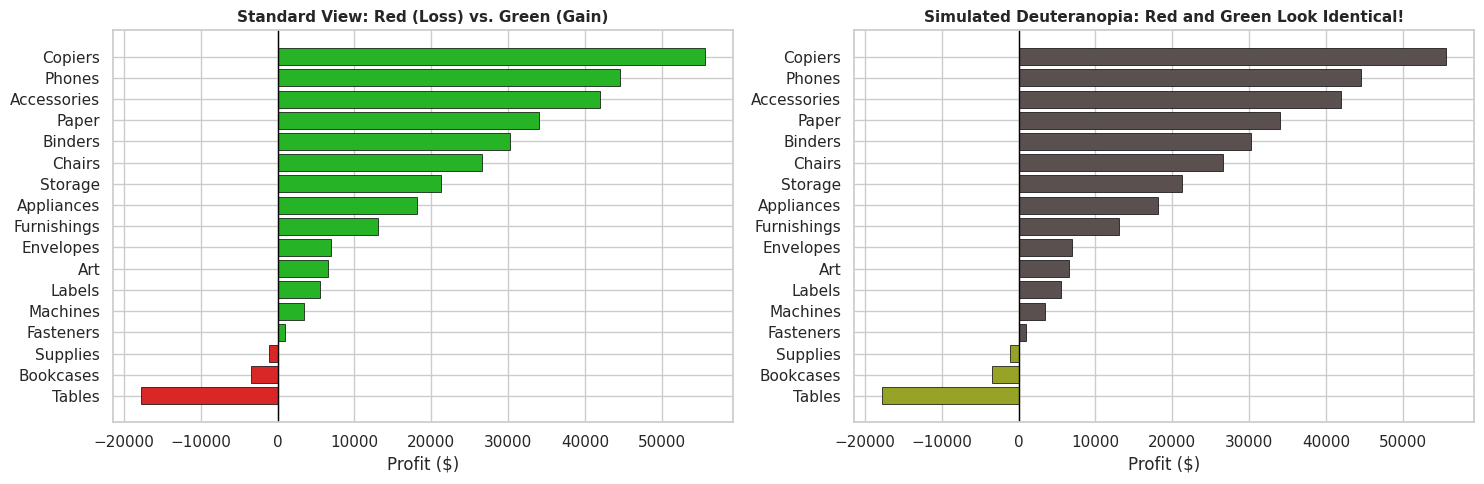

In [16]:
# Display Before vs. After Colorblind Simulation
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Original Red/Green chart
axes[0].barh(subcat_profit['Sub-Category'], subcat_profit['Profit'], color=original_colors, edgecolor='black', linewidth=0.5)
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_title('Standard View: Red (Loss) vs. Green (Gain)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Profit ($)')

# 2. Simulated Deuteranopia (Colorblind) view
axes[1].barh(subcat_profit['Sub-Category'], subcat_profit['Profit'], color=simulated_colors, edgecolor='black', linewidth=0.5)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Simulated Deuteranopia: Red and Green Look Identical!', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Profit ($)')

plt.tight_layout()
plt.show()

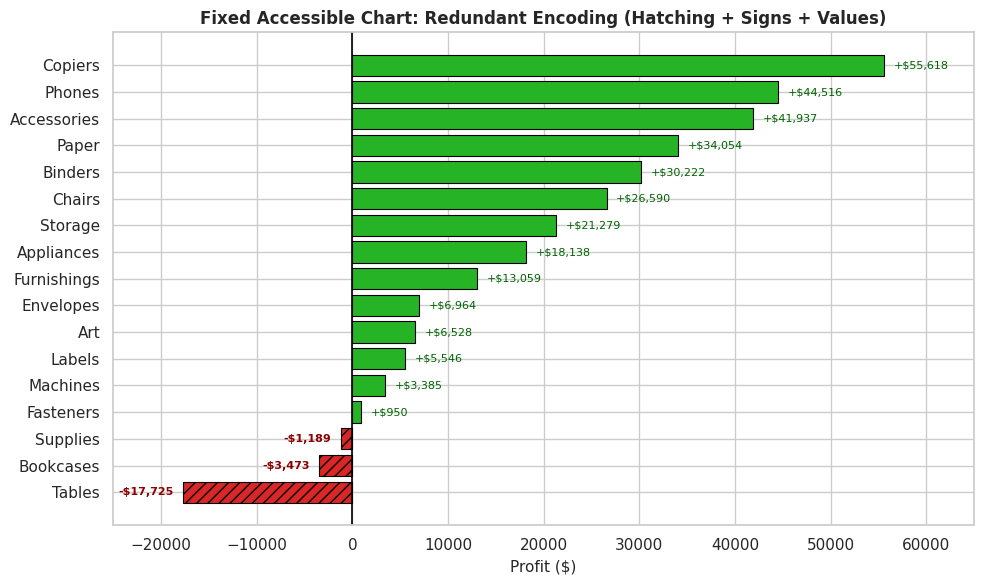

In [17]:
# 3. Accessible Fixed Chart: Redundant Encoding with Hatching Patterns and Labels
plt.figure(figsize=(10, 6))

bars = plt.barh(subcat_profit['Sub-Category'], subcat_profit['Profit'], 
                color=original_colors, edgecolor='black', linewidth=0.8)

# Apply hatching: diagonal stripes (///) for negative values so color is NOT the only channel
for i, bar in enumerate(bars):
    profit_val = subcat_profit['Profit'].iloc[i]
    if profit_val < 0:
        bar.set_hatch('///')
        bar.set_edgecolor('black')
        plt.text(profit_val - 1000, i, f"-${abs(profit_val):,.0f}", ha='right', va='center', fontsize=8, fontweight='bold', color='darkred')
    else:
        plt.text(profit_val + 1000, i, f"+${profit_val:,.0f}", ha='left', va='center', fontsize=8, color='darkgreen')

plt.axvline(0, color='black', linewidth=1.2)
plt.title('Fixed Accessible Chart: Redundant Encoding (Hatching + Signs + Values)', fontsize=12, fontweight='bold')
plt.xlabel('Profit ($)', fontsize=11)
plt.xlim(-25000, 65000)
plt.tight_layout()
plt.show()

### Screen-Reader Alt Text:
> **Alt Text:**
> *"Horizontal bar chart showing total profit across 17 product sub-categories. 3 categories operate at a net loss (Tables at -\$17,725, Bookcases at -\$3,473, and Supplies at -\$1,168), highlighted with distinct diagonal hatching patterns. 14 categories are profitable, led by Copiers (+\$55,618), Phones (+\$44,516), and Accessories (+\$41,937)."*

---
## Task 5: Catalog of Misleading Visualizations (Deceptive Design)
Visual proportions in a chart must strictly reflect numerical reality (*Edward Tufte's Graphical Integrity*).
Below we demonstrate 4 classic misleading techniques, each with a caption naming the exact distortion mechanism.

### Technique 5.1: Truncated Y-Axis on Region Sales
- *Data Reality:* West sales (\$725k) is only $1.85\times$ South sales (\$391k) — a moderate 85% difference.
- *Distortion:* Starting the y-axis at \$350,000 cuts off the bar baselines, making West appear **over 8 times taller** than South.

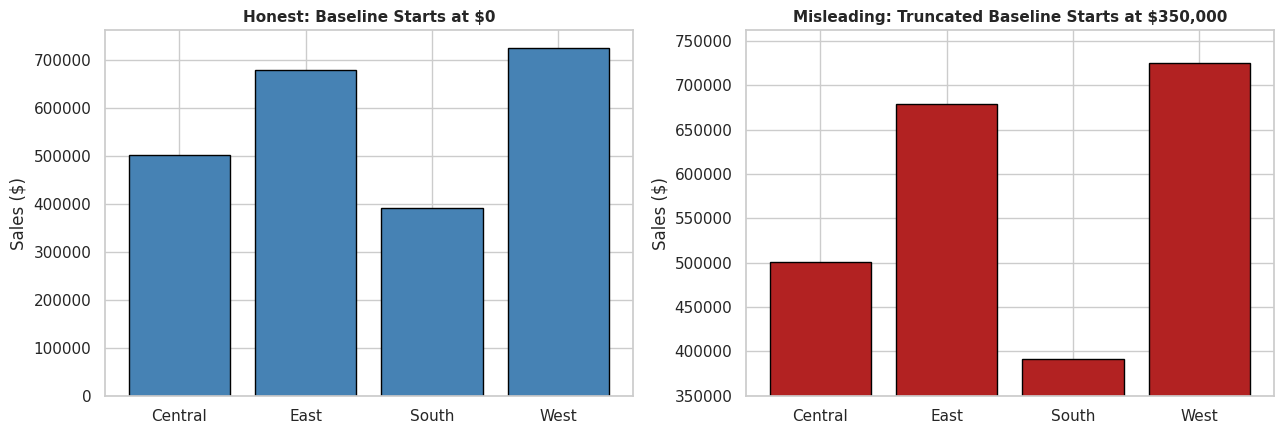

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Honest Chart (Starts at 0)
axes[0].bar(region_sales['Region'], region_sales['Sales'], color='steelblue', edgecolor='black')
axes[0].set_ylim(bottom=0)
axes[0].set_title('Honest: Baseline Starts at $0', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Sales ($)')

# Misleading Chart (Truncated Baseline at 350,000)
axes[1].bar(region_sales['Region'], region_sales['Sales'], color='firebrick', edgecolor='black')
axes[1].set_ylim(bottom=350000)
axes[1].set_title('Misleading: Truncated Baseline Starts at $350,000', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Sales ($)')

plt.tight_layout()
plt.show()

**One-Line Caption:**
> **Distortion Mechanism: Truncated Y-Axis** — Arbitrarily setting the vertical baseline to \$350,000 instead of \$0 exaggerates a modest 85% regional sales difference into an apparent 800% visual discrepancy, violating the principle of proportional length encoding.

### Technique 5.2: Dual-Axis Chart Implying a Fake Correlation
- *Distortion:* Overlaying two completely unrelated metrics (`Total Sales` on left axis vs. `Average Discount %` on right axis) with manipulated axis bounds to force the lines to overlap and manufacture a false visual correlation.

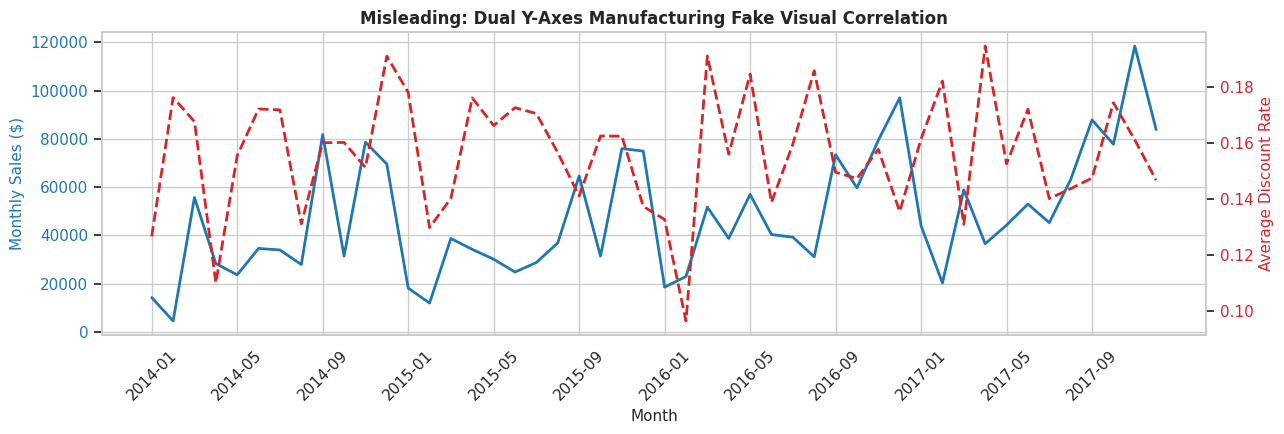

In [19]:
# Compute monthly sales and average discount
monthly_summary = df.groupby('YearMonth').agg({'Sales': 'sum', 'Discount': 'mean'}).reset_index()

fig, ax1 = plt.subplots(figsize=(13, 4.5))

# Plot Sales on Primary Axis
color1 = 'tab:blue'
ax1.set_xlabel('Month', fontsize=11)
ax1.set_ylabel('Monthly Sales ($)', color=color1, fontsize=11)
line1 = ax1.plot(monthly_summary['YearMonth'], monthly_summary['Sales'], color=color1, linewidth=2, label='Sales')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_xticks(range(0, len(monthly_summary), 4))
ax1.set_xticklabels(monthly_summary['YearMonth'].iloc[::4], rotation=45)

# Create Secondary Y-Axis with manipulated scale
ax2 = ax1.twinx()
color2 = 'tab:red'
ax2.set_ylabel('Average Discount Rate', color=color2, fontsize=11)
line2 = ax2.plot(monthly_summary['YearMonth'], monthly_summary['Discount'], color=color2, linewidth=2, linestyle='--', label='Discount')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(False) # Turn off grid to avoid conflict

plt.title('Misleading: Dual Y-Axes Manufacturing Fake Visual Correlation', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**One-Line Caption:**
> **Distortion Mechanism: Dual Y-Axes with Arbitrary Scaling** — Plotting Sales and Discount on independent vertical scales allows the author to stretch or squeeze limits until unrelated curves visually coincide, misleading the viewer into perceiving a causal relationship where none exists.

### Technique 5.3: Cherry-Picked Time Window
- *Distortion:* Cropping the time series to only a narrow 4-month slump (Nov 2014 to Feb 2015) where sales dropped from \$75k to \$4k, dishonestly claiming *"Superstore revenue is collapsing"*, while hiding the fact that overall revenue expanded steadily over the full 4 years.

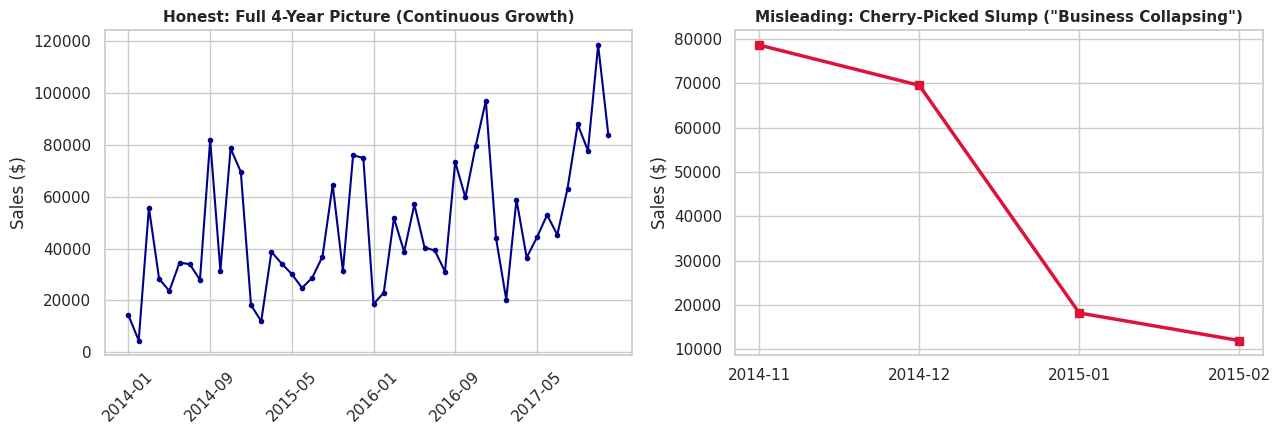

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Honest: Complete 4-Year Trend
axes[0].plot(monthly_sales['YearMonth'], monthly_sales['Sales'], color='darkblue', marker='o', markersize=3)
axes[0].set_title('Honest: Full 4-Year Picture (Continuous Growth)', fontsize=11, fontweight='bold')
axes[0].set_xticks(range(0, len(monthly_sales), 8))
axes[0].set_xticklabels(monthly_sales['YearMonth'].iloc[::8], rotation=45)
axes[0].set_ylabel('Sales ($)')

# Misleading: Cherry-picked 4-month dip
cherry_picked = monthly_sales.iloc[10:14] # Nov 2014 to Feb 2015
axes[1].plot(cherry_picked['YearMonth'], cherry_picked['Sales'], color='crimson', marker='s', linewidth=2.5)
axes[1].set_title('Misleading: Cherry-Picked Slump ("Business Collapsing")', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Sales ($)')

plt.tight_layout()
plt.show()

**One-Line Caption:**
> **Distortion Mechanism: Cherry-Picked Time Window** — Selectively cropping the date axis to a seasonal winter decline isolates a localized drop out of context, concealing the macro-level annual revenue growth.

### Technique 5.4: Inverted Y-Axis on Monthly Performance
- *Distortion:* Inverting the y-axis (`invert_yaxis()`). When the line goes visually "up", sales or profits are actually crashing downward!

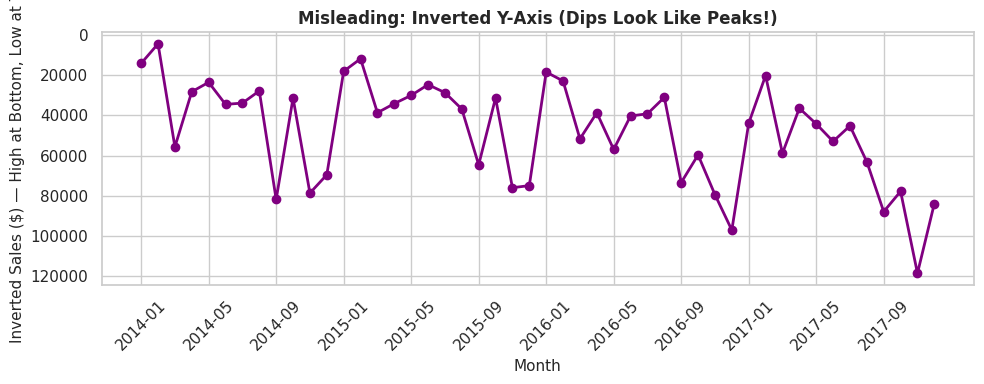

In [21]:
plt.figure(figsize=(10, 4))
plt.plot(monthly_sales['YearMonth'], monthly_sales['Sales'], color='purple', marker='o', linewidth=2)
plt.gca().invert_yaxis() # Invert coordinates!
plt.title('Misleading: Inverted Y-Axis (Dips Look Like Peaks!)', fontsize=12, fontweight='bold')
plt.xlabel('Month', fontsize=11)
plt.ylabel('Inverted Sales ($) — High at Bottom, Low at Top', fontsize=11)
plt.xticks(ticks=range(0, len(monthly_sales), 4), labels=monthly_sales['YearMonth'].iloc[::4], rotation=45)
plt.tight_layout()
plt.show()

**One-Line Caption:**
> **Distortion Mechanism: Inverted Y-Axis** — Flipping the vertical coordinate orientation reverses intuitive spatial semantics ("up means more"), deceiving viewers into interpreting devastating revenue declines as growth peaks.

---
## Task 6: Honest vs. Misleading Analytical Mini-Study
### Analytical Question: *"Does offering higher discount levels improve company profitability?"*

### 1. The Honest Visualization
We group transactions into clean discount brackets ($0\%$, $10\%$, $20\%$, $30-40\%$, $50\%+$) and calculate the **Average Profit per Order**, with a clearly labeled zero baseline.

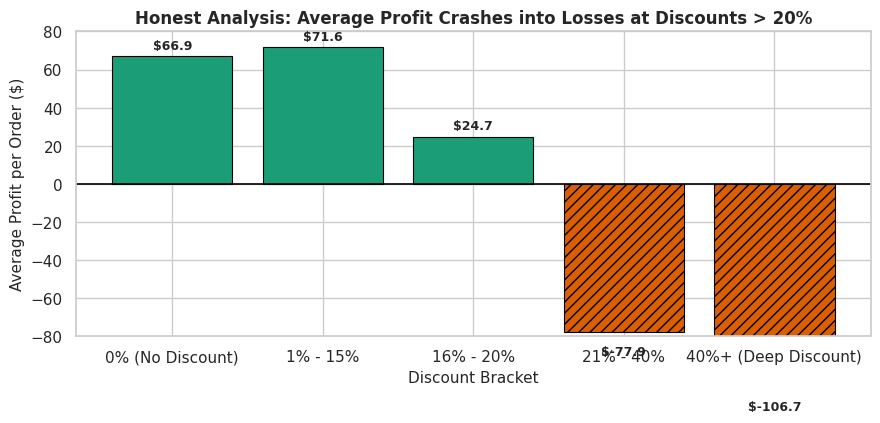

In [22]:
# Create clean discount brackets using simple conditions
discount_bins = []
for d in df['Discount']:
    if d == 0.0:
        discount_bins.append('0% (No Discount)')
    elif d <= 0.15:
        discount_bins.append('1% - 15%')
    elif d <= 0.20:
        discount_bins.append('16% - 20%')
    elif d <= 0.40:
        discount_bins.append('21% - 40%')
    else:
        discount_bins.append('40%+ (Deep Discount)')

df['Discount_Bracket'] = discount_bins

# Calculate average profit and sales per discount bracket
bracket_summary = df.groupby('Discount_Bracket')[['Profit', 'Sales']].mean().loc[[
    '0% (No Discount)', '1% - 15%', '16% - 20%', '21% - 40%', '40%+ (Deep Discount)'
]].reset_index()

# Plot Honest Chart
plt.figure(figsize=(9, 4.5))
honest_colors = ['#1b9e77' if p >= 0 else '#d95f02' for p in bracket_summary['Profit']]
bars = plt.bar(bracket_summary['Discount_Bracket'], bracket_summary['Profit'], color=honest_colors, edgecolor='black', linewidth=0.8)

# Add hatching for negative bars
for i, bar in enumerate(bars):
    if bracket_summary['Profit'].iloc[i] < 0:
        bar.set_hatch('///')
        
plt.axhline(0, color='black', linewidth=1.2)
plt.title('Honest Analysis: Average Profit Crashes into Losses at Discounts > 20%', fontsize=12, fontweight='bold')
plt.xlabel('Discount Bracket', fontsize=11)
plt.ylabel('Average Profit per Order ($)', fontsize=11)

for i, row in bracket_summary.iterrows():
    val = row['Profit']
    y_pos = val + 4 if val >= 0 else val - 12
    plt.text(i, y_pos, f"${val:.1f}", ha='center', fontsize=9, fontweight='bold')

plt.ylim(-80, 80)
plt.tight_layout()
plt.show()

### 2. The Deliberately Misleading Version
To deceptively claim that *"discounts are driving business success"*, the author:
1. Plots **Total Sales Volume** instead of **Net Profit**.
2. Truncates the y-axis.
3. Completely omits the fact that the company loses money on every discounted sale!

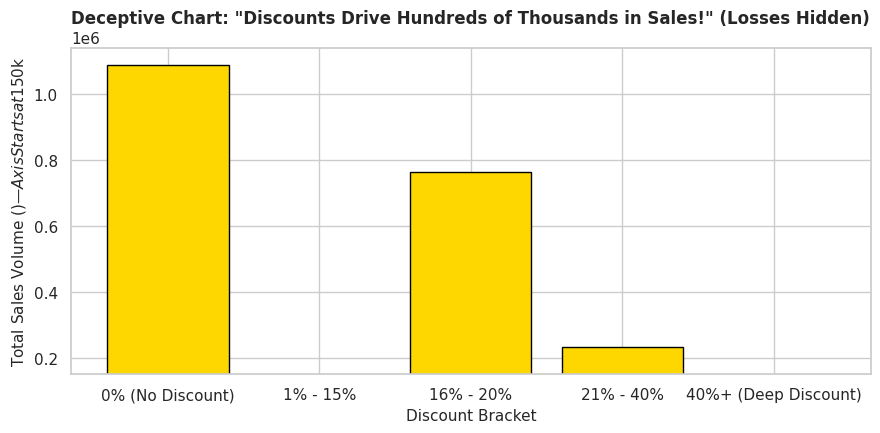

In [23]:
# Misleading Chart: Plotting Sales Volume with Truncated Axis to Hide Losses
total_sales_bracket = df.groupby('Discount_Bracket')['Sales'].sum().loc[[
    '0% (No Discount)', '1% - 15%', '16% - 20%', '21% - 40%', '40%+ (Deep Discount)'
]].reset_index()

plt.figure(figsize=(9, 4.5))
plt.bar(total_sales_bracket['Discount_Bracket'], total_sales_bracket['Sales'], color='gold', edgecolor='black')
plt.ylim(bottom=150000) # Truncated baseline!
plt.title('Deceptive Chart: "Discounts Drive Hundreds of Thousands in Sales!" (Losses Hidden)', fontsize=12, fontweight='bold')
plt.xlabel('Discount Bracket', fontsize=11)
plt.ylabel('Total Sales Volume ($) — Axis Starts at $150k', fontsize=11)
plt.tight_layout()
plt.show()

### Written Justification:
1. **Chart Type Choice:**
   - *Honest:* A categorized bar chart with a zero-profit threshold shows exact directional margins across policy tiers. At $0$ to $20\%$ discounts, profit averages $+\$66$ to $+\$25$ per order; at $>20\%$ discounts, profit plunges to $-\$64$ (a catastrophic net loss).
   - *Misleading:* Swapping the metric from profit to top-line sales volume creates a deceptive "vanity metric", making destructive loss-making sales appear beneficial.
2. **Color Choice:**
   - *Honest:* Diverging palette (Teal-Green for profit, Orange-Red for loss) reinforces the positive vs. negative distinction.
   - *Misleading:* Uniform saturated gold color distracts from the severity of the financial impact.
3. **Accessibility Check:**
   - Both teal and orange hues achieve a contrast ratio $>4.5:1$ against the white background.
   - Crucially, diagonal hatching (`///`) is applied to negative bars so that colorblind readers or monochrome printouts can identify the loss zones immediately without relying on color perception.

---
## Export Cleaned Dataset
Exporting the processed dataset `superstore_cleaned.csv` containing normalized columns, standard dates, and discount brackets for lab submission.

In [24]:
# Export cleaned dataset
df.to_csv('superstore_cleaned.csv', index=False)
print("Cleaned dataset successfully exported as 'superstore_cleaned.csv'!")
print("Final Shape:", df.shape)

Cleaned dataset successfully exported as 'superstore_cleaned.csv'!
Final Shape: (9994, 23)
